# Late Deliveries: analysis

How common late orders are, how the candidate models compare, how the threshold was chosen from the scenario's costs, and the honest test-set result.

In [1]:
import sys

sys.path.insert(0, "../src")
import json

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay

from latedeliveries.data import make_orders

frame = make_orders()
frame.head()

,order_id,distance_km,items,hour,weather,day_type,vehicle,prep_minutes,courier_months,customer_rating,late
0,100000,3.4,2,13,rain,weekend,bike,13.6,48,4.0,0
1,100001,2.7,2,12,rain,weekday,scooter,11.7,2,4.0,0
2,100002,2.4,4,13,clear,weekend,scooter,22.4,53,3.0,1
3,100003,3.5,1,17,clear,weekend,bike,12.5,39,NaN,0
4,100004,2.3,5,11,clear,weekend,car,5.9,9,5.0,0


## How common are late orders?

Late rate: 15.6% (468 of 3000 orders)


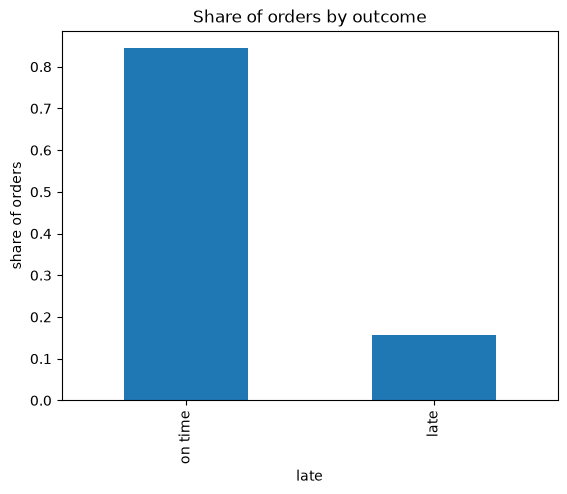

In [2]:
late_rate = frame["late"].mean()
print(f"Late rate: {late_rate:.1%} ({frame['late'].sum()} of {len(frame)} orders)")
frame["late"].value_counts(normalize=True).rename({0: "on time", 1: "late"}).plot(
    kind="bar", title="Share of orders by outcome"
)
plt.ylabel("share of orders")
plt.show()

In [3]:
frame.isna().mean().loc[lambda s: s > 0].rename("share missing")

prep_minutes       0.063000
customer_rating    0.496333
Name: share missing, dtype: float64

About one order in six arrives late, matching the scenario. `prep_minutes` and `customer_rating` have missing values, which is one more reason `customer_rating` (missing for half the orders, and only recorded after delivery) is unusable as a feature.

## Comparing models

Five-fold stratified cross-validation on the training data only (see `src/latedeliveries/train.py`). Results are also written to `reports/cv_results.csv`.

In [4]:
cv_results = pd.read_csv("../reports/cv_results.csv")
cv_results

,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,baseline_most_frequent,0.844000,0.000889,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.000000
1,logistic_regression,0.862222,0.008074,0.661105,0.068253,0.239316,0.027664,0.351333,0.039123,0.788538,0.036325
2,logistic_regression_balanced,0.738667,0.015938,0.332565,0.026587,0.672153,0.065336,0.444796,0.037282,0.788134,0.036788
3,random_forest,0.854222,0.006379,0.601691,0.078955,0.207928,0.016425,0.307945,0.021859,0.756211,0.036198


`logistic_regression_balanced` was chosen: its ROC-AUC (ability to rank orders by late risk) is essentially tied with plain logistic regression and clearly ahead of the random forest, and its recall is far higher (about 0.67 vs 0.24), which matters because missing a late order costs $15 while flagging one costs only $4. `GridSearchCV` over `C` and `solver` then barely moved ROC-AUC (0.7889 tuned vs 0.7881 +/- 0.0368 untuned), well inside the fold-to-fold spread, so tuning did not meaningfully beat the default settings here.

## Choosing the threshold from costs

Out-of-fold probabilities from the training data only, scored against the scenario's cost rule for every threshold from 0.05 to 0.95.

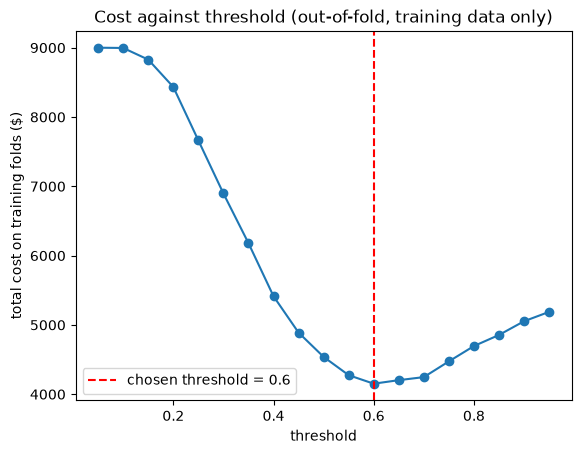

In [5]:
with open("../reports/metrics.json") as f:
    metrics = json.load(f)

cost_table = pd.DataFrame(metrics["cost_table"])
plt.plot(cost_table["threshold"], cost_table["cost"], marker="o")
plt.axvline(
    metrics["threshold"],
    color="red",
    linestyle="--",
    label=f"chosen threshold = {metrics['threshold']}",
)
plt.xlabel("threshold")
plt.ylabel("total cost on training folds ($)")
plt.title("Cost against threshold (out-of-fold, training data only)")
plt.legend()
plt.show()

## Test-set result (scored once)

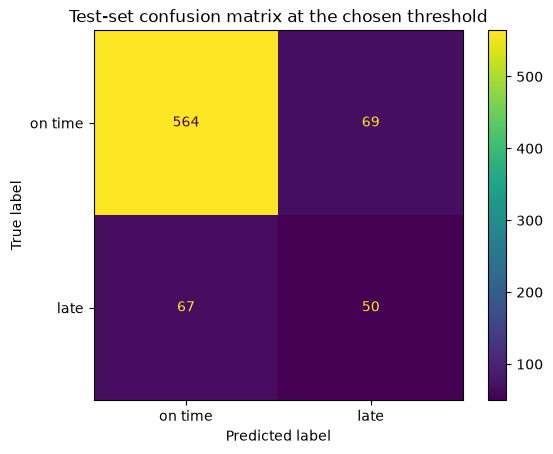

{'confusion_matrix': [[564, 69], [67, 50]],
 'precision': 0.42016806722689076,
 'recall': 0.42735042735042733,
 'f1': 0.423728813559322,
 'roc_auc': 0.7519477187723632}

In [6]:
cm = metrics["test_metrics"]["confusion_matrix"]
ConfusionMatrixDisplay(
    confusion_matrix=pd.DataFrame(cm).values, display_labels=["on time", "late"]
).plot()
plt.title("Test-set confusion matrix at the chosen threshold")
plt.show()
metrics["test_metrics"]

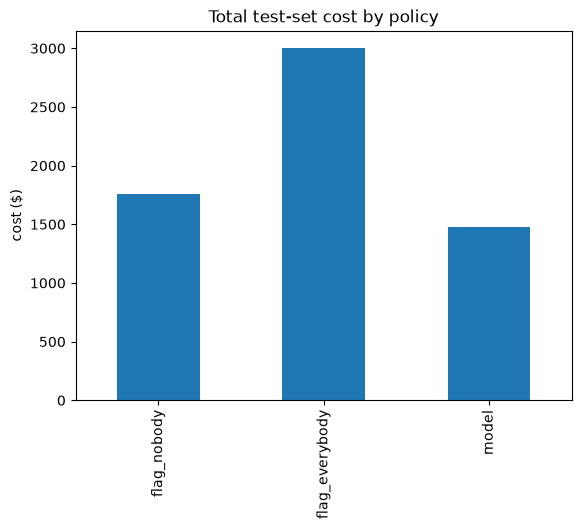

flag_nobody       1755.0
flag_everybody    3000.0
model             1481.0
dtype: float64

In [7]:
policy_costs = pd.Series(metrics["policy_costs"])
policy_costs.plot(kind="bar", title="Total test-set cost by policy")
plt.ylabel("cost ($)")
plt.show()
policy_costs

## Recommendation

**Would you use this model?** Yes. Flagging with the model costs $1,481 on the test set, versus $1,755 for flagging nobody (today's policy) and $3,000 for flagging everybody - a real reduction with no change in company process beyond sending a voucher.

**Why this threshold?** 0.6 was the point on the training-only, out-of-fold cost curve that minimised the scenario's cost ($4 per voucher, $15 per missed late order); it is not the default 0.5 cut-off and was never chosen by looking at the test set.

**What did you exclude and why?** `order_id` (an identifier), `prep_minutes` (not known until the kitchen finishes, after the order is placed) and `customer_rating` (missing for half the orders and only given after the order has already arrived; in this simulated data it is even partly derived from `late` itself). Adding `prep_minutes` and `customer_rating` back lifts CV ROC-AUC from 0.79 to about 0.92 - a sharp, suspicious jump that confirms they leak the outcome.

**One limitation:** recall is about 0.43 at this threshold, so more than half of late orders still go unflagged; a model with a cheaper false-negative cost, or more features known at order time (e.g. current kitchen backlog), would likely do better.